# **STEP 2, PART 1**
### ***Seeing whether everything works before doing a convergence test.***

LAB data itself is the reference and the comparison is linear in brightness temperature, as in Marasco+12:

First, we look at whether the model and LAB cubes are comparable, with LAB being the reference.

1. LAB and model are smoothed to **8 degrees** (with convolution over the kept regions, so the masked disk does not leak).
2. Only the **halo region** is compared (flat rotation curve at 220 km/s, |v_dev| < 30 km/s, Outer Arm, GCP, external galaxies, Magellanic System, Leading Arm, MS stream).
3. The model is **normalised so that its total flux in that region equals LAB's** (after smoothing, on the comparison grid).
4. Three residuals are summed over the voxels (weights $w = \cos(b)$, the pixel solid angle):
   * absolute: $R_{\rm abs} = \sum w |D - M|$,
   * squared: $R_{\rm sq} = \sum w (D - M)^2$,
   * relative: $R_{\rm rel} = \sum w |D - M| / (D + M + \epsilon)$, $\epsilon = 0.04 K$ (LAB noise level).

The model with the smallest residual is the best.

Each residual is divided by its minimum over the models compared (as the paper's convention). The data-side uncertainty of each residual is the leave-one-longitude-sector-out **jackknife** (flux scale recomputed on the rest, which is new).

**What we wish to check before convergence or fitting:**
* what LAB and the model look like side by side at 8 degrees (l-v slices, channel maps),
* whether they are comparable voxel by voxel, in latitude and in velocity, and where the model is brighter or fainter,
* what each residual is dominated by (a few bright clumps or many voxels),
* whether the three residuals agree on the ordering of models, using the `f_ion` probe runs (`f_ion = 0.3, 0.6, 1.0`),
* whether Marasco+12 Table 1 can be reproduced: neutral, ionised and condensation fountain at hv = 70 km/s, alpha_hv = 0, which should give the paper's ordering (neutral > ionized > condensation).

In [ ]:
import sys, time, pickle
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

sys.path.insert(1, "../EPG_Code/current_version_software")
sys.path.insert(1, "../EPG_Code/mw_addenda")
sys.path.insert(1, "../EPG_Code/fitting")

from mw_io import load_npz, load_lab_clean
from mw_display import Cube
from mw_cube import mirror_north_to_full_sky
from mw_mask import (disk_velocity_envelope, mask_disk_emission, mask_named_regions,
                     flat_v_circ, OUTER_ARM, GCP, EXTERNAL_GAL, MAGELLANIC)

from marasco_comp import *

LAB_PATH = "../Displays/lab.fit.gz"
GRID = Path("./grid")                   # the grid-search cubes (f_ion probes, stage Q/B ...)
CONV = Path("./conv")                   # the convergence-study cubes (tiers 1-4)
B_CUT = 0
L_CUT = 0
REL_FLOOR = 0.04                        # K: softening of the relative residual (see the module docstring)
N_REF = 40                              # n_per_bin of the convergence reference group
HV_STEP = 5.0                           # km/s between the N and D groups of the convergence study (60 -> 65)

cfg = CompareConfig(beam_fwhm=8.0, sampling=4.0, dv=8.0)       # Marasco+12: everything smoothed to 8 degrees

We prepare the LAB data. Here the masks are made and applied to LAB, but there is an option to apply a `B_CUT` and an `L_CUT`.

In [ ]:
def build_keep(cube_data, axes, bcut=None):
    l, b, v = axes
    bc = B_CUT if bcut is None else bcut
    vmin, vmax = disk_velocity_envelope(l, b, R0=8.275, v_circ_func=flat_v_circ(220.0))
    excl = mask_disk_emission(cube_data, v, vmin, vmax, v_dev_threshold=40.0, return_mask_only=True)
    excl |= mask_named_regions(l, b, v, [OUTER_ARM, GCP] + EXTERNAL_GAL + MAGELLANIC)
    excl |= (np.abs(b) < bc)[None, :, None]
    if L_CUT > 0: excl |= (np.abs((np.asarray(l, float) + 180.0) % 360.0 - 180.0) < L_CUT)[None, None, :]
    return ~excl

def to_full(cube_north, axes):
    full = mirror_north_to_full_sky(Cube(cube_north, *axes, "model"))
    return full.data, (full.l, full.b, full.v)

def load_model(name, folder):
    cube, l, b, v = load_npz(Path(folder) / f"{name}.npz")
    return cube, (l, b, v)

lab, l_lab, b_lab, v_lab = load_lab_clean(LAB_PATH)
ax_lab = (l_lab, b_lab, v_lab); keep_lab = build_keep(lab, ax_lab)
cmp = MarascoComparison(lab, ax_lab, keep_lab, build_keep, to_full, cfg, rel_floor=REL_FLOOR)
print(f"Comparison grid: {len(cmp.v)} channels x {len(cmp.b)} b x {len(cmp.l)} l; "
      f"{int(np.isfinite(cmp.lab_cmp.data).sum())} LAB voxels with data")

Comparison grid: 62 channels x 41 b x 90 l; 159702 LAB voxels with data


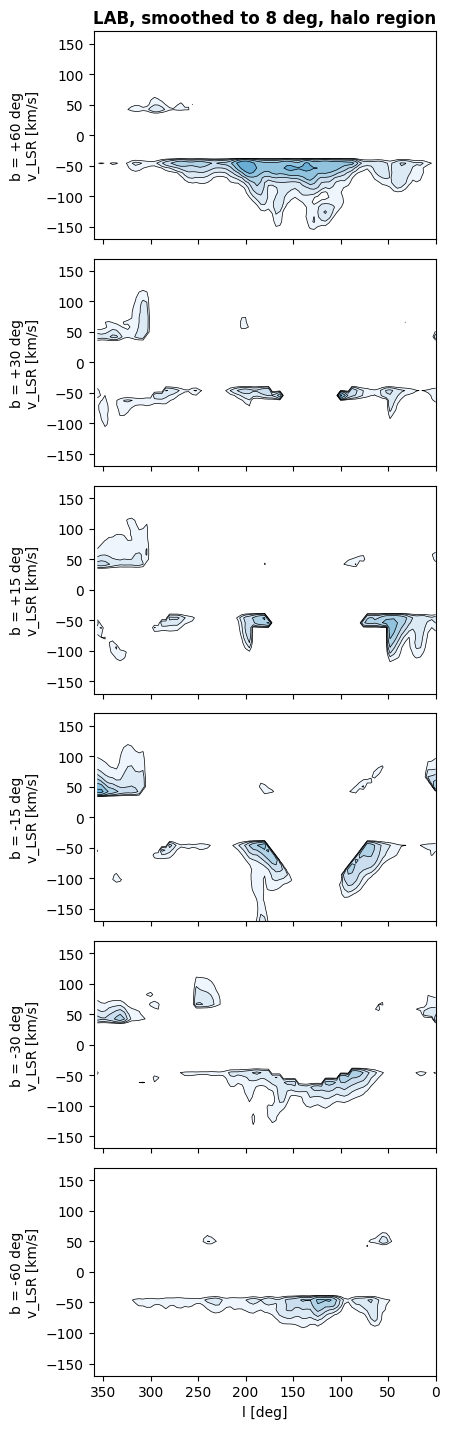

In [3]:
lab_cmp = cmp.lab_cmp
f = plot_lv_slices([(lab_cmp, "LAB, smoothed to 8 deg, halo region")], b_targets=(60, 30, 15, -15, -30, -60))
plt.show()

## Models to Compare
From previous tests, we have some `f_ion` probe runs from the grid search (`F0_*`: hv0 = 70, alpha_conds = 6.3, alpha_hv = 0.2; `F1_*`: hv0 = 112, alpha_conds = 2, alpha_hv = 0.49; each at `f_ion = 0.3, 0.6, 1.0`, two seeds, `n_per_bin = 40`) and one convergence cube (`N160_s11` with `n_per_bin = 160`). They are evaluated with the Marasco comparison.

In [4]:
RES = {}; MODS = {}

def evaluate_models(names, folder, keep_vec_for=()):
    for nm in names:
        f = Path(folder) / f"{nm}.npz"
        if nm in RES or not f.exists():
            continue
        cube, ax = load_model(nm, folder)
        mod = cmp.model_cmp(cube, ax)
        RES[nm] = cmp.evaluate(mod, keep_vectors=(nm in keep_vec_for)); MODS[nm] = mod

probe = [f"F{p}_f{int(round(100*fi)):03d}_s{k}" for p in (0, 1) for fi in (0.3, 0.6, 1.0) for k in (0, 1)]

t0 = time.time()
evaluate_models(probe, GRID, keep_vec_for=("F0_f030_s0", "F0_f100_s0", "F1_f030_s0"))
print(f"{len(RES)} models evaluated in {time.time()-t0:.0f} s")

if (CONV / "N160_s11.npz").exists():
    evaluate_models(["N160_s11"], CONV, keep_vec_for=("N160_s11",))

12 models evaluated in 21 s


Run 0: hv0 =  70, alpha_conds = 6.3, alpha_hv = 0.20
model name          R_abs   /min       R_sq   /min      R_rel   /min    scale  jackknife rel. error (abs / sq / rel)
F0_f030_s0         2542.1  1.000      660.8  1.000    18834.0  1.000   17.792  0.090 / 0.204 / 0.043
F0_f030_s1         2599.9  1.023      704.6  1.066    19057.8  1.012   19.181  0.085 / 0.203 / 0.037
F0_f060_s0         2643.2  1.040      695.3  1.052    19336.8  1.027   20.444  0.081 / 0.192 / 0.040
F0_f060_s1         2700.7  1.062      744.5  1.127    19572.4  1.039   21.187  0.079 / 0.193 / 0.037
F0_f100_s0         2746.3  1.080      722.6  1.093    20046.7  1.064   22.307  0.073 / 0.184 / 0.038
F0_f100_s1         2810.7  1.106      772.7  1.169    20394.3  1.083   22.824  0.071 / 0.186 / 0.036

   abs : f_ion 0.3 / 0.6 / 1.0 -> 1.000 / 1.039 / 1.081   (lower f_ion better)
   sq  : f_ion 0.3 / 0.6 / 1.0 -> 1.000 / 1.055 / 1.095   (lower f_ion better)
   rel : f_ion 0.3 / 0.6 / 1.0 -> 1.000 / 1.027 / 1.067   (lower 

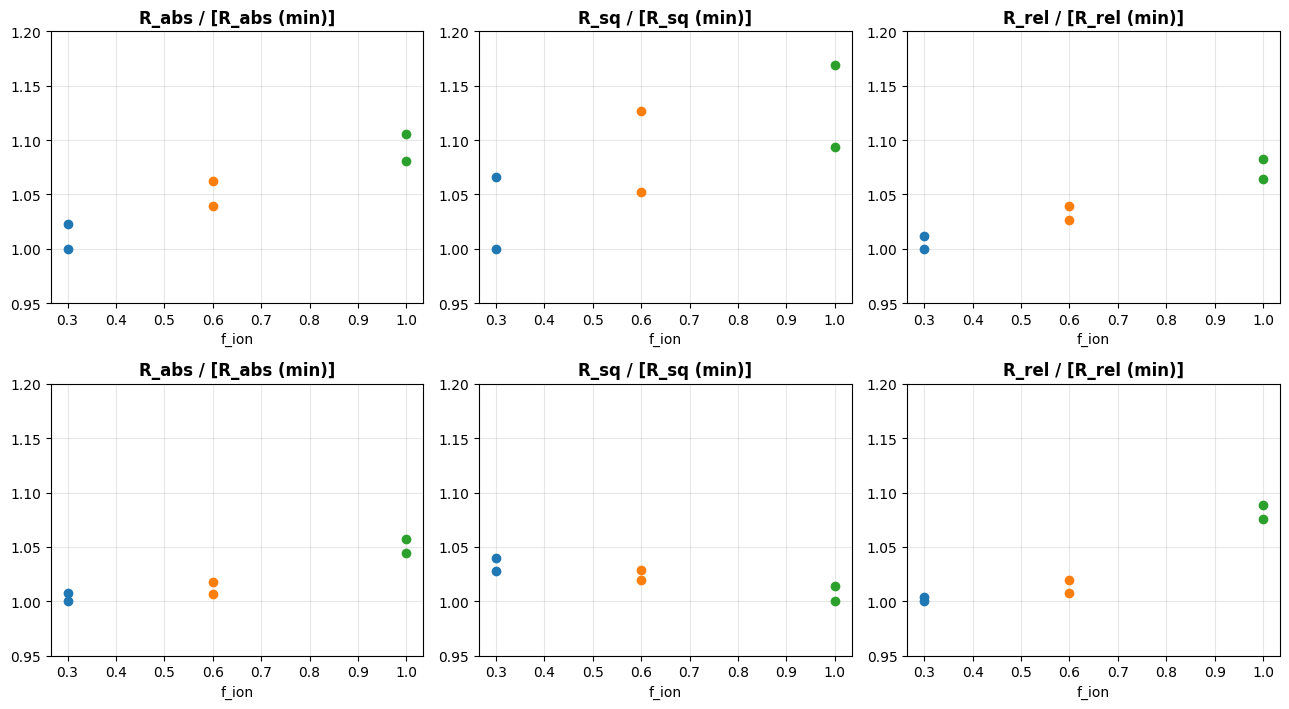

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 3, figsize=(13, 3.6*2))
x_coord = [0.3, 0.3, 0.6, 0.6, 1.0, 1.0]

for p, ax, label in ((0, ax1, "Run 0: hv0 =  70, alpha_conds = 6.3, alpha_hv = 0.20"), 
                     (1, ax2, "Run 1: hv0 = 112, alpha_conds = 2.0, alpha_hv = 0.49")):
    
    names = [f"F{p}_f{int(round(100*fi)):03d}_s{k}" for fi in (0.3, 0.6, 1.0) for k in (0, 1) 
             if f"F{p}_f{int(round(100*fi)):03d}_s{k}" in RES]
    
    if not names: 
        continue

    print(f"{label}")
    print(f"{'model name':14s} " + 
          " ".join(f"{'R_'+k:>10s} {'/min':>6s}" for k in OBS) + 
          f"  {'scale':>7s}  jackknife rel. error (abs / sq / rel)")

    mins = {k: min(RES[n]["R_" + k] for n in names) for k in OBS}

    for idx, n in enumerate(names):
        jk = [jackknife_rel_error(RES[n]["R_" + k], RES[n]["R_loo"][i]) for i, k in enumerate(OBS)]
        print(f"{n:14s} " + 
              " ".join(f"{RES[n]['R_'+k]:10.1f} {RES[n]['R_'+k]/mins[k]:6.3f}" for k in OBS) + 
              f"  {RES[n]['scale']:7.3f}  " + " / ".join(f"{x:.3f}" for x in jk))

        R_abs, R_sq, R_rel = [RES[n]['R_'+k]/mins[k] for k in OBS]
        color = ["tab:blue", "tab:blue", "tab:orange", "tab:orange", "tab:green", "tab:green"]
        ax[0].plot(x_coord[idx], R_abs, "o", c=color[idx])
        ax[1].plot(x_coord[idx], R_sq, "o", c=color[idx])
        ax[2].plot(x_coord[idx], R_rel, "o", c=color[idx])

    print()
    for a, k in zip(ax, OBS):
        m = {fi: np.mean([RES[n]["R_" + k] for n in names 
                          if f"_f{int(round(100*fi)):03d}_" in n]) for fi in (0.3, 0.6, 1.0)}
        
        print(f"   {k:4s}: f_ion 0.3 / 0.6 / 1.0 -> " + 
              " / ".join(f"{m[fi]/min(m.values()):.3f}" for fi in (0.3, 0.6, 1.0)) 
              + ("   (lower f_ion better)" if m[0.3] < m[0.6] < m[1.0] else "   (ordering differs)" if True else ""))

        a.set_title(f"R_{k} / [R_{k} (min)]", weight="bold")

    print()

    for a in ax: 
        a.set_ylim(0.95, 1.2)
        a.set_xlabel("f_ion")
        a.grid(alpha=0.3)

plt.tight_layout()
plt.show()

For the same absolute contour levels everywhere (0.04 K x 2^n), the model scaled to LAB's flux in the halo region, we once again compare the shape of the emission, the velocity extent, and the latitude behaviour.

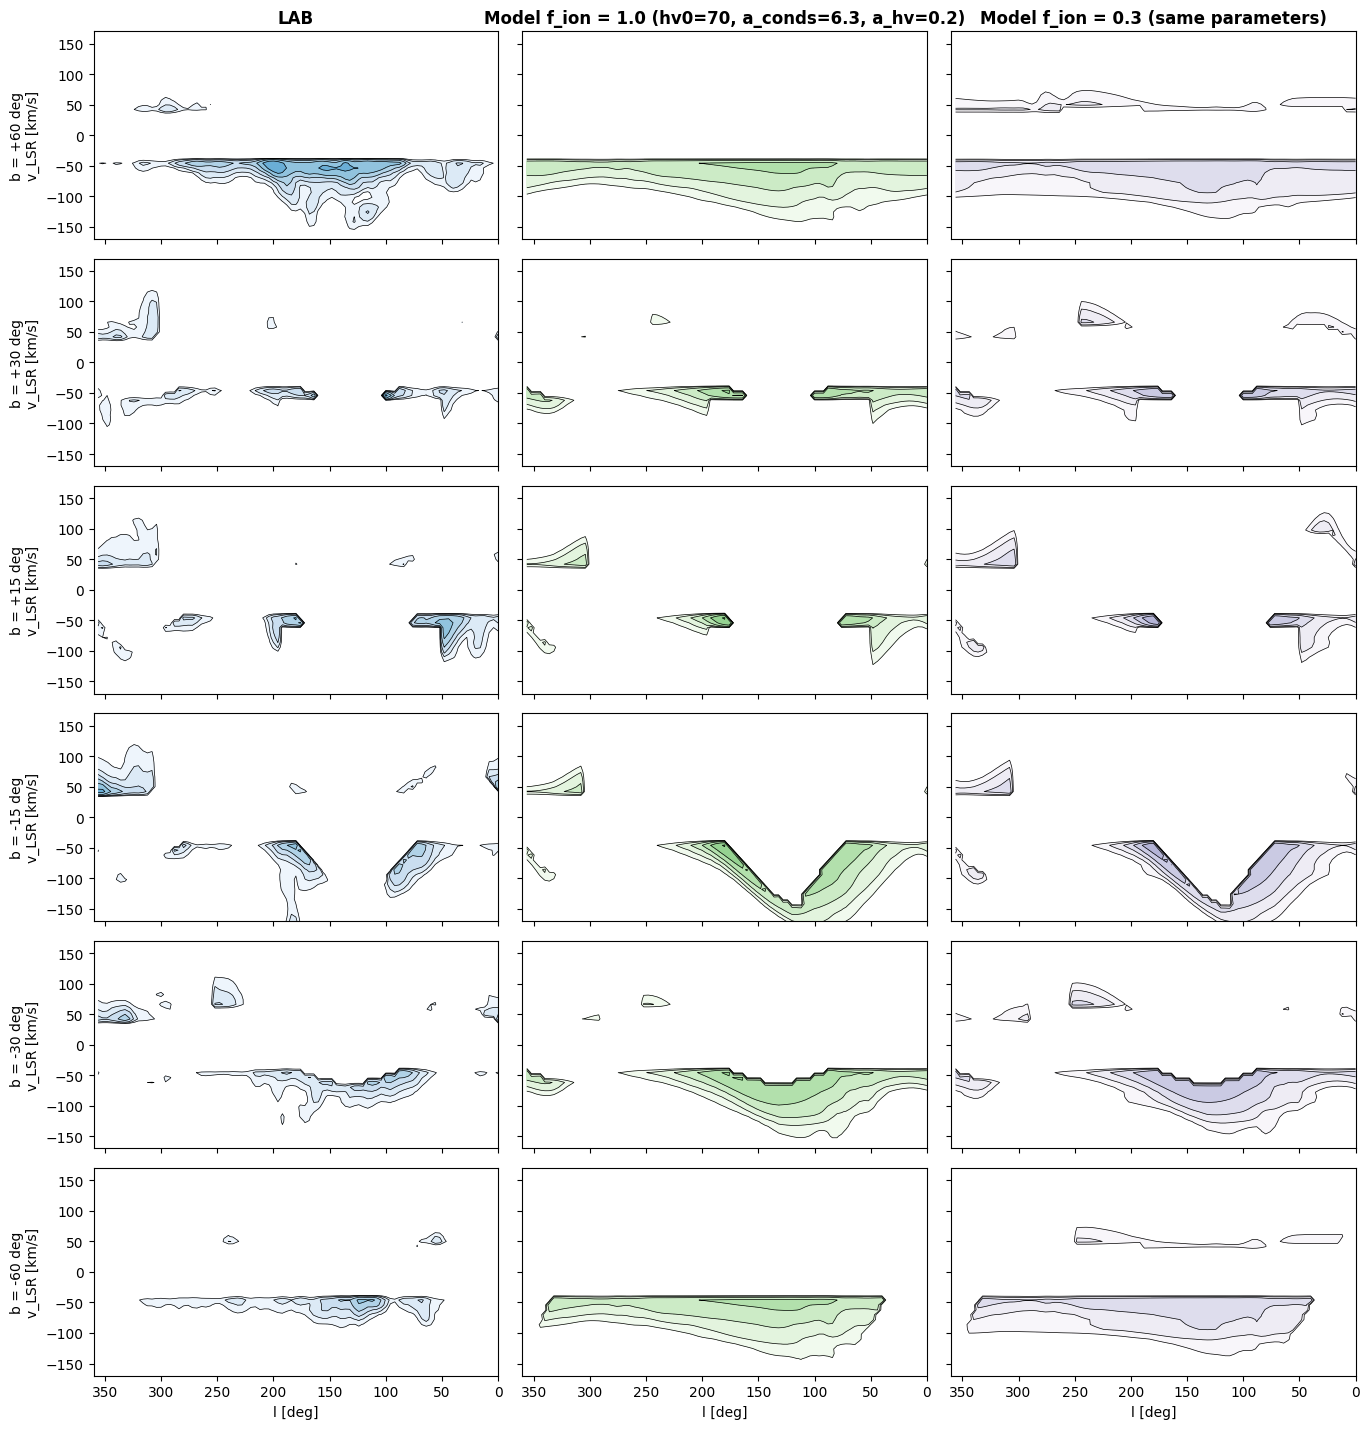

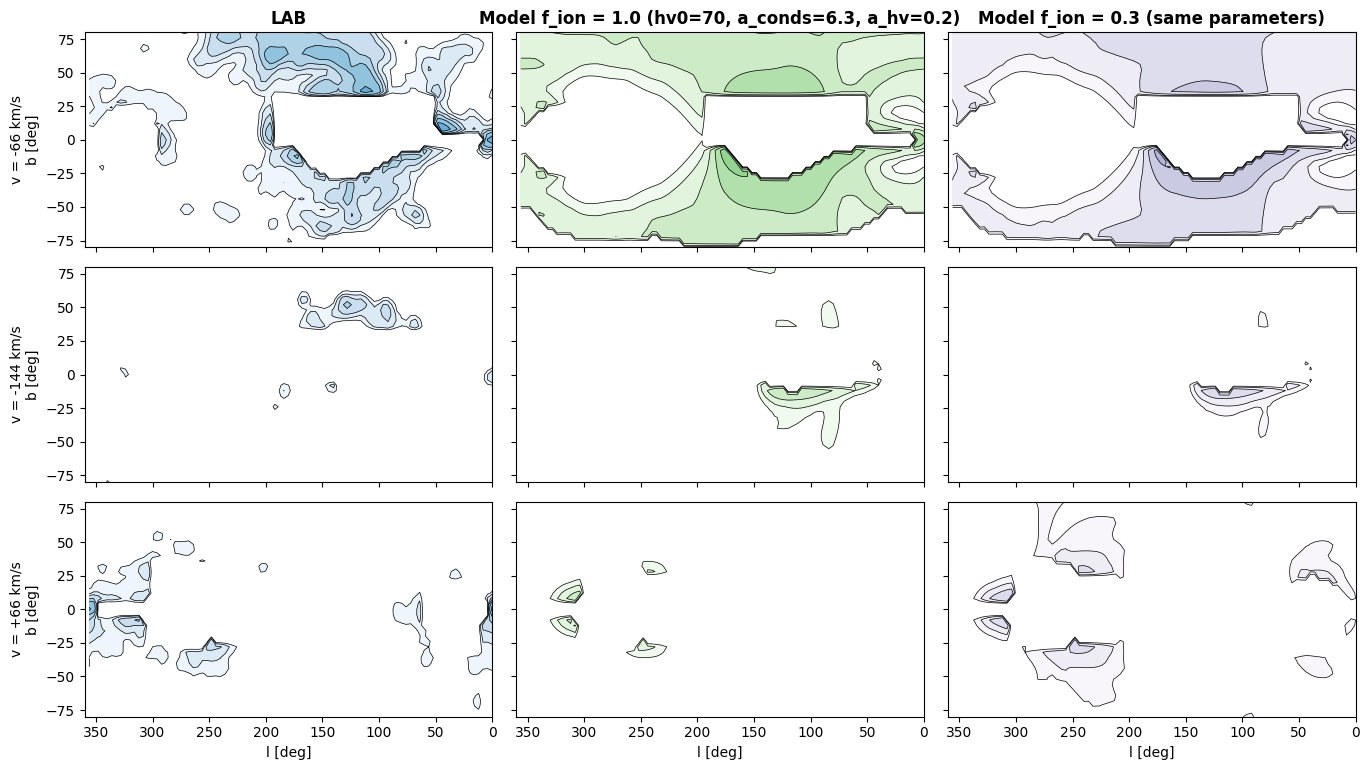

In [6]:
panels = [(cmp.lab_cmp, "LAB"),
          (cmp.scaled(MODS["F0_f100_s0"], RES["F0_f100_s0"]["scale"]), "Model f_ion = 1.0 (hv0=70, a_conds=6.3, a_hv=0.2)"),
          (cmp.scaled(MODS["F0_f030_s0"], RES["F0_f030_s0"]["scale"]), "Model f_ion = 0.3 (same parameters)")]

plot_lv_slices(panels, b_targets=(60, 30, 15, -15, -30, -60))
plt.show()

plot_channel_maps(panels, v_targets=(-66.0, -144.0, 66.0))
plt.show()

## Are they comparable?
#### Voxel by voxel, in latitude and velocity, and what dominates each residual

We have six panels per model: 
1. LAB against model for every voxel, 
2. the ratio distribution where the model is bright, 
3. the share of the flux in latitude bands,
4. the share of the flux in velocity bands, 
5. the signed residual map (model - LAB integrated over velocity),
6. the cumulative share of each residual carried by the largest-contributing voxels. 

The last panel shows how each residual gets overwhelmed by bright voxels (as fractions of total voxels considered, largest to smallest).

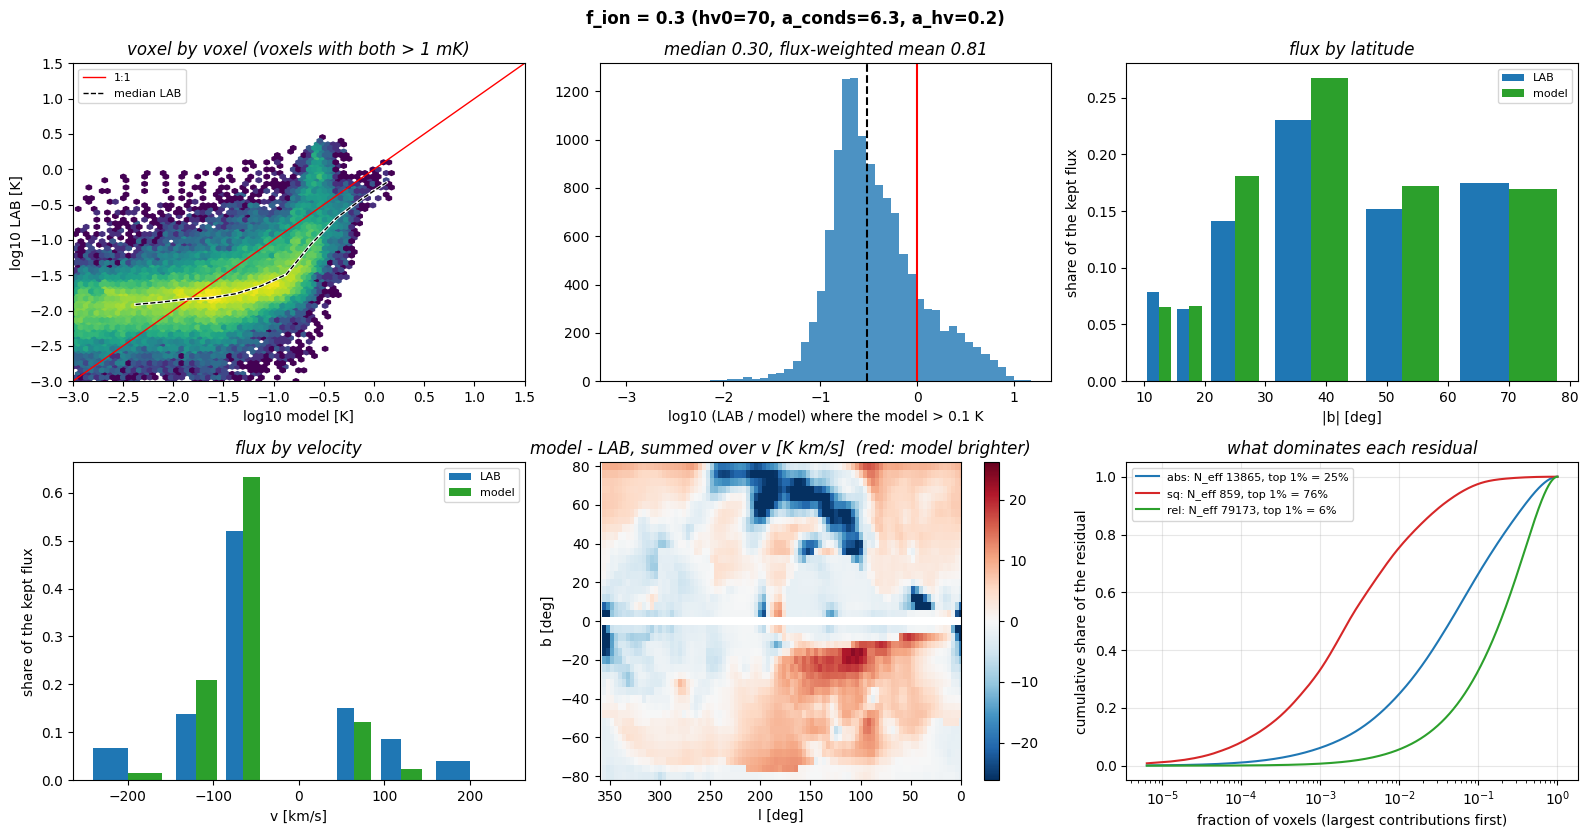

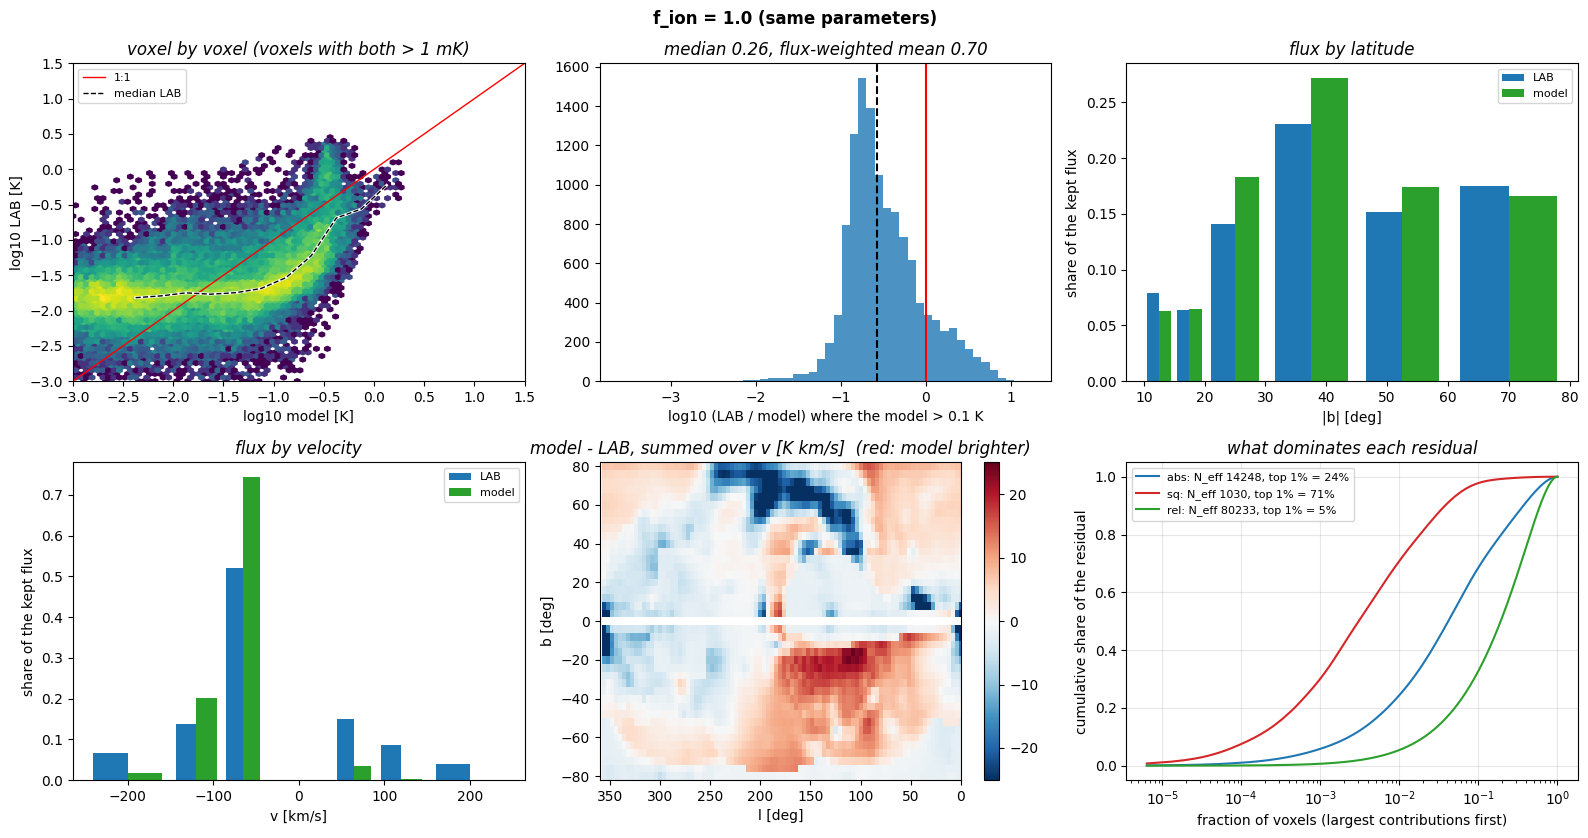

In [7]:
for nm, ttl in (("F0_f030_s0", "f_ion = 0.3 (hv0=70, a_conds=6.3, a_hv=0.2)"), 
                ("F0_f100_s0", "f_ion = 1.0 (same parameters)")):
    if nm in RES and "vec" in RES[nm]:
        plot_comparability(cmp, MODS[nm], RES[nm], title=ttl)
        plt.show()

A quick check for `R_rel` with a different denominators depending on $\epsilon$. The ordering of models should not. If it does, the relative residual is not a robust observable. We see that is mostly doesn't, but it becomes to indistinguishable for $\epsilon > 0.04$ K which is the noise level of LAB.

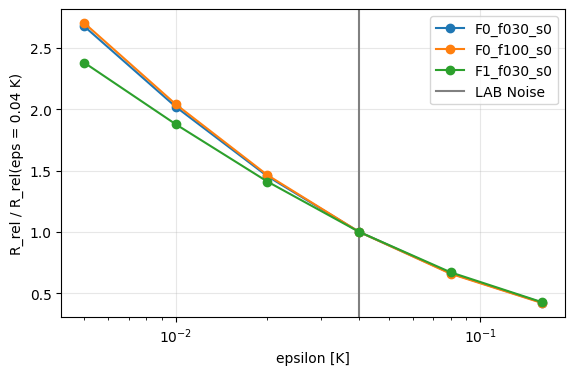

In [8]:
floors = (0.005, 0.01, 0.02, 0.04, 0.08, 0.16)
fig, ax = plt.subplots(figsize=(6.5, 4))
for nm in ("F0_f030_s0", "F0_f100_s0", "F1_f030_s0"):
    if nm in RES and "vec" in RES[nm]:
        c = rel_floor_curve(RES[nm]["vec"], floors)
        ax.plot(floors, c / c[3], "o-", label=nm, zorder=10)

ax.axvline(0.04, color="gray", label="LAB Noise")
ax.set_xscale("log")
ax.set_xlabel("epsilon [K]")
ax.set_ylabel("R_rel / R_rel(eps = 0.04 K)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## Reproduction Test of Marasco+12 Table 1
We need to see if we can reproduce Table 1 in a roughly agreeable manner.

Three fountain models with the paper's setup is:

| model | `hv0`| `f_ion` | `alpha_conds` | linear residuals | residual ratio |
| ----- | ---- | ------- | -------------| ------------------| ---------------|
| pure | 70 | 0 | 0 | 1.60 | 1.27 |
| ionized | 70 | 1.0 | 0 | 1.48 | 1.17 | 
| condensation | 70 | 0.3 | 6.3 | 1.26 | 1 |


We have 3 seeds each at `n_per_bin = 160`. If our cubes and this comparison are right, the ordering in the paper's absolute-difference residual is **neutral > ionised > condensation** with ratios of about 1.27 and 1.17 relative to the condensation model. The three residuals are all computed here, so we can see which of them reproduces the ordering.

observable        neutral        ionised   condensation      | ratio to condensation:  neutral  ionised   (paper: 1.27, 1.17)
       abs    2802.8+-0.5%    2879.6+-1.3%    2587.8+-0.1%   |                           1.083    1.113
        sq     776.9+-1.1%     833.1+-3.1%     648.5+-0.4%   |                           1.198    1.285
       rel   19580.4+-0.4%   19771.9+-1.1%   19128.4+-0.1%   |                           1.024    1.034


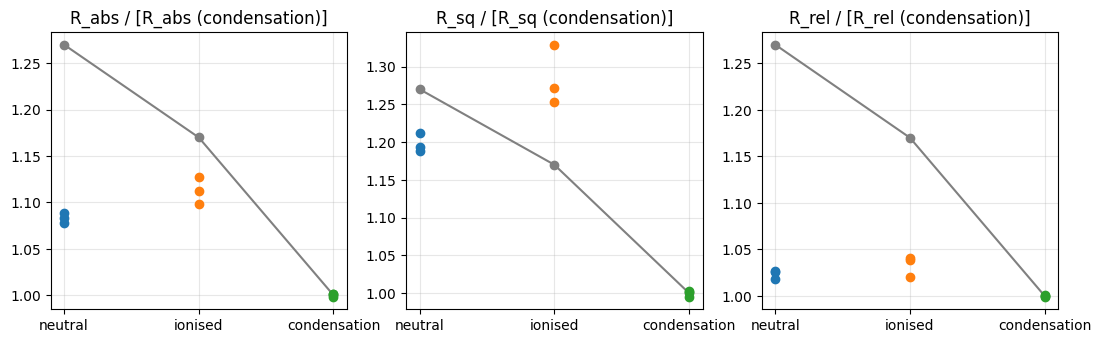

In [9]:
M_INDEX = 2000
LABELS = {0: "neutral", 1: "ionised", 2: "condensation"}

names_M = [f"M{M_INDEX + i:04d}" for i in range(9)]
done = [n for n in names_M if (GRID / f"{n}.npz").exists()]

evaluate_models(names_M, GRID)
groups = {LABELS[g]: names_M[3 * g:3 * g + 3] for g in range(3)}

print(f"{'observable':>10s} " + " ".join(f"{k:>14s}" for k in groups) 
      + "      | ratio to condensation:  neutral  ionised   (paper: 1.27, 1.17)")

for k in OBS:
    m = {g: np.mean([RES[n]["R_" + k] for n in nm]) for g, nm in groups.items()}
    s = {g: np.std([RES[n]["R_" + k] for n in nm], ddof=1) / m[g] for g, nm in groups.items()}
    print(f"{k:>10s} " + " ".join(f"{m[g]:9.1f}+-{100*s[g]:3.1f}%" for g in groups) + 
          f"   |                          {m['neutral']/m['condensation']:6.3f}   {m['ionised']/m['condensation']:6.3f}")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, k in zip(ax, OBS):
    for j, (g, nm) in enumerate(groups.items()):
        v = np.array([RES[n]["R_" + k] for n in nm])
        a.plot([j] * 3, v / np.mean([RES[n]["R_" + k] for n in groups["condensation"]]), "o", zorder=10)

    a.plot([0, 1, 2], [1.27, 1.17, 1], "o-", c="gray")
    a.set_xticks(range(3))
    a.set_xticklabels(list(groups))
    a.set_title(f"R_{k} / [R_{k} (condensation)]")
    a.grid(alpha=0.3)
plt.show()

## Why is the ordering not the paper's?

With this, we make an important discovery that the model does not behave as how Marasco+12 would lead us to predict. The condensation model is clearly the best in all three residuals, as in the paper, but **ionised is worse than neutral** in all three (about 2-3 sigma with 3 seeds each), whereas the paper has neutral worst. 

Because the three residuals agree with each other, the observable is not the cause. Something in the model, the masks, or the setup is. There are 3 things that come to mind that one can check:

1. **Which positive-velocity gas does LAB have in our mask?** 
    The ionised fountain shows only falling gas (v < 0 at high |b|), the neutral one also the rising gas (v > 0). If our mask leaves more positive-velocity halo emission than the paper's, neutral wins. 

2. **Is our masks too different than the paper's mask?** 
    Re-evaluate the nine cubes with increasing |l| and |b| cuts to see if this is an insufficient masking error. If it is and the cause is improperly masked GC/bar, then the residuals should agree with Marasco+12 until we start masking out more gas than necessary and damage our results.

3. **The meaning of f_ion in the code.** 
    In the paper, `f_ion = 1` means the cloud is ionised during the whole ascent and neutral on the way down. This should be the same in our code too, but it is good to check.

---

**1.** We compare the flux share at positive and negative velocity at high latitude |b| > 30 deg. The expectation is the ionised fountain should have almost nothing at v > 0 if `f_ion = 1` means neutral only while falling.

The expectations are mostly matched with what we see, so this cannot be an explanation.

In [10]:
# 1. flux share at positive and negative velocity, high latitude: LAB and the three Table-1 models (|b| >= 30 deg)
def v_shares(vec, cmp_obj, bmin=30.0):
    valid = vec["valid"]; shp = valid.shape
    bb = np.broadcast_to(np.abs(cmp_obj.b)[None, :, None], shp)[valid]
    vv = np.broadcast_to(cmp_obj.v[:, None, None], shp)[valid]
    w = vec["w"]; sel = bb >= bmin
    out = {}
    for lab_, arr in (("LAB", vec["d"]), ("model", vec["m"])):
        tot = (w[sel] * arr[sel]).sum()
        out[lab_] = dict(pos=(w[sel & (vv > 0)] * arr[sel & (vv > 0)]).sum() / tot, 
                         pos40=(w[sel & (vv > 40)] * arr[sel & (vv > 40)]).sum() / tot,
                         neg40=(w[sel & (vv < -40)] * arr[sel & (vv < -40)]).sum() / tot)
    return out

rows = {}
for g, lab_name in LABELS.items():
    nm = names_M[3 * g]
    cube, ax = load_model(nm, GRID)
    mod = cmp.model_cmp(cube, ax)
    r = cmp.evaluate(mod, keep_vectors=True)
    rows[lab_name] = v_shares(r["vec"], cmp)

print(f"Flux share at |b| >= 30 deg:     v > 0    v > +40   v < -40")
print(f"   {'LAB':14s}              {100*rows['neutral']['LAB']['pos']:6.1f}%   {100*rows['neutral']['LAB']['pos40']:6.1f}%   {100*rows['neutral']['LAB']['neg40']:6.1f}%")

for k in LABELS.values():
    print(f"   {k:14s}              {100*rows[k]['model']['pos']:6.1f}%   {100*rows[k]['model']['pos40']:6.1f}%   {100*rows[k]['model']['neg40']:6.1f}%")

Flux share at |b| >= 30 deg:     v > 0    v > +40   v < -40
   LAB                           20.1%     20.1%     79.9%
   neutral                       52.8%     52.8%     47.2%
   ionised                        4.7%      4.7%     95.3%
   condensation                  18.0%     18.0%     82.0%


**2.** Now, we look at if our masks have non-matching parts or we have forgotten to mask some parts of the model.

In Marasco+12, the halo region is everything with |v_DEV| > 35 km/s against a flat 220 km/s disc model (R0 = 8.5 kpc), minus the Magellanic System, the Leading Arm, the GCP complex, the Outer Arm and the external galaxies. No |b| cut and no |l| cut.

The envelope assumes circular orbits. The Galactic bar and the non-circular gas in the inner few kpc (|l| of order 30 deg and below) have line-of-sight velocities outside that envelope, so they are kept as `halo'. The fountain model is axisymmetric and cannot produce them, and the neutral fountain, which has gas at v > 0, can match some of it. We do the same for |b| for sake of completeness.

**(a)** the l-v diagrams of what is left, with the mask edges drawn. <br>
**(b)** where in l each model gains or loses against the others. <br>
**(c)** the exact scan: remove |l| < cut from LAB and from the models, recompute everything, and see the ratios.

From a plateau in (c) and from the physical extent of the bar (roughly |l| of 25-30 deg), but not from the cut that makes Table 1 come out, which would be circular. 

We must watch the ionised/condensation ratio as well: if it drifts to 1 when the cut grows, the discrimination between those two lives in the inner Galaxy and a cut that fixes neutral against ionised costs the condensation signal.

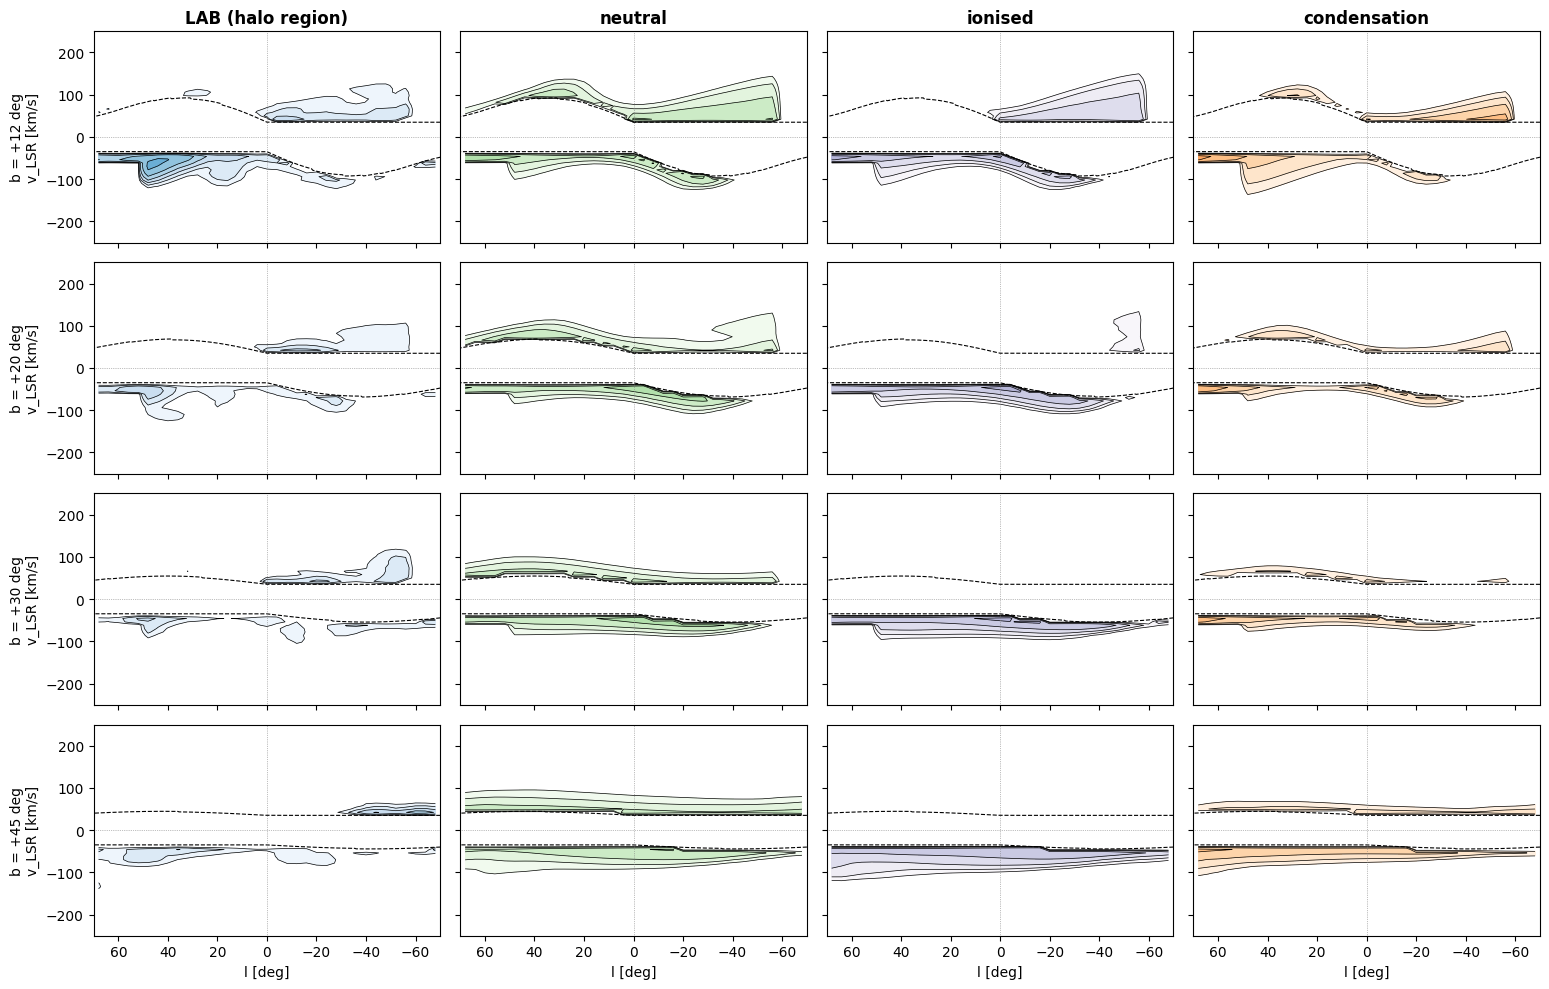

In [11]:
# (a) what is left in the inner Galaxy: l-v diagrams centred on l = 0
def envelope_overlay(ax, bt):
    lg = np.linspace(-70.0, 70.0, 281)
    vmin, vmax = disk_velocity_envelope(lg, np.array([float(bt)]), R0=8.275, v_circ_func=flat_v_circ(220.0))
    ax.plot(lg, vmin[0] - 35.0, "k--", lw=0.8)
    ax.plot(lg, vmax[0] + 35.0, "k--", lw=0.8)
    # dashed: the edges of the v_DEV mask (everything between them is masked)
    if L_CUT > 0: ax.axvline(L_CUT, color="r", lw=0.8); ax.axvline(-L_CUT, color="r", lw=0.8)

evaluate_models(names_M, GRID)
sc = lambda n: cmp.scaled(MODS[n], RES[n]["scale"])
panels = [(cmp.lab_cmp, "LAB (halo region)"), 
          (sc(names_M[0]), "neutral"), 
          (sc(names_M[3]), "ionised"), 
          (sc(names_M[6]), "condensation")]

plot_inner_lv(panels, b_targets=(12, 20, 30, 45), lmax=70, overlay=envelope_overlay)
plt.show()

R_abs: share of tot. neut-ion diff. @ |l| < 30:  226.1%   (tot. -0.030);   ion-cond:  108.1%   (tot. +0.113)
R_sq : share of tot. neut-ion diff. @ |l| < 30:  194.0%   (tot. -0.087);   ion-cond:   76.7%   (tot. +0.285)
R_rel: share of tot. neut-ion diff. @ |l| < 30:  227.9%   (tot. -0.010);   ion-cond:   80.2%   (tot. +0.034)


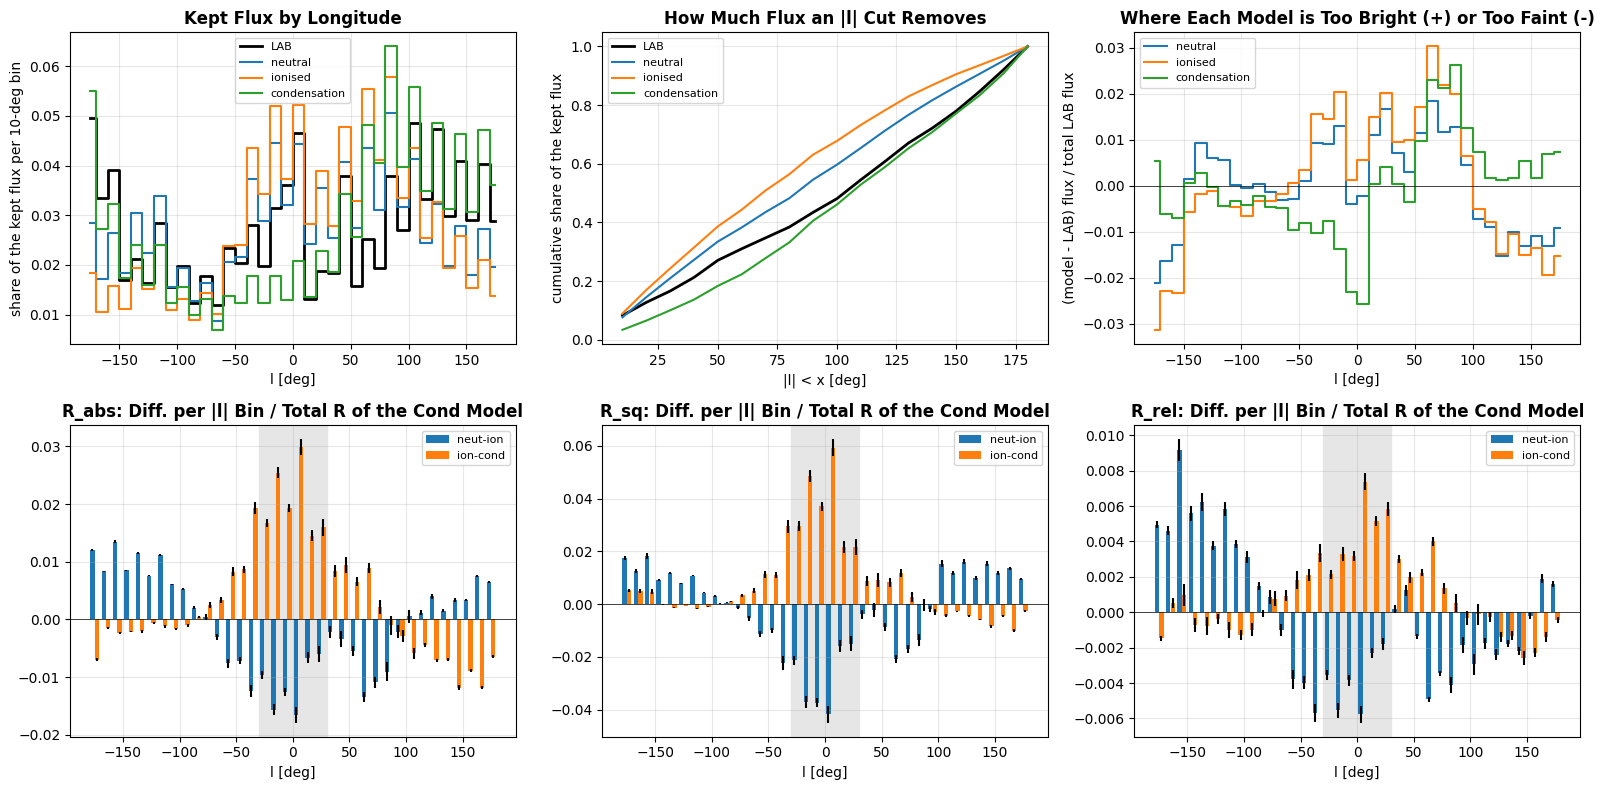

Bottom row: positive bars = the first model of the pair is worse in that bin. Grey band: |l| < 30 deg.


In [12]:
# (b) where in longitude does each model gain or lose
BASE = globals().get("BASE", {})

def share_by_l(cmp_obj, res):
    """LAB and model flux (weighted sums over the kept voxels) in the 10-degree longitude bins L_BINS; 
    needs evaluate(keep_vectors=True)."""

    vec = res["vec"]; valid = vec["valid"]
    lw = np.broadcast_to(((cmp_obj.l + 180.0) % 360.0 - 180.0)[None, None, :], valid.shape)[valid]

    w, d, m = vec["w"], vec["d"], vec["m"]
    sel = [(lw >= lo) & (lw < hi) for lo, hi in zip(L_BINS[:-1], L_BINS[1:])]

    return (np.array([(w * d)[s].sum() for s in sel]), 
            np.array([(w * m)[s].sum() for s in sel]),
            np.array([s.sum() for s in sel]))

for g in range(3):
    for j, nm in enumerate(names_M[3 * g:3 * g + 3]):
        if nm in BASE: continue
        cube, ax_ = load_model(nm, GRID); BASE[nm] = cmp.evaluate(cmp.model_cmp(cube, ax_), keep_vectors=(j == 0))

lc = 0.5 * (L_BINS[:-1] + L_BINS[1:]); wbin = np.diff(L_BINS)
share = {LABELS[g]: share_by_l(cmp, BASE[names_M[3 * g]]) for g in range(3)}
fl_lab = share["neutral"][0]; tot = fl_lab.sum()

fig, axs = plt.subplots(2, 3, figsize=(16, 8))
ax = axs[0, 0]
ax.step(lc, fl_lab / tot, where="mid", color="k", lw=2, label="LAB")

for (name, (fl, fm, nv)), c in zip(share.items(), ("C0", "C1", "C2")):
    ax.step(lc, fm / fm.sum(), where="mid", color=c, label=name)

ax.set_xlabel("l [deg]")
ax.set_ylabel("share of the kept flux per 10-deg bin")
ax.set_title("Kept Flux by Longitude", weight="bold")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axs[0, 1]

al = np.abs(lc); xs = np.arange(10, 181, 10.0)
ax.plot(xs, [fl_lab[al < x].sum() / tot for x in xs], "k-", lw=2, label="LAB")

for (name, (fl, fm, nv)), c in zip(share.items(), ("C0", "C1", "C2")): 
    ax.plot(xs, [fm[al < x].sum() / fm.sum() for x in xs], color=c, label=name)

ax.set_xlabel("|l| < x [deg]"); ax.set_ylabel("cumulative share of the kept flux")
ax.set_title("How Much Flux an |l| Cut Removes", weight="bold")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axs[0, 2]
for (name, (fl, fm, nv)), c in zip(share.items(), ("C0", "C1", "C2")):
    ax.step(lc, (fm - fl) / tot, where="mid", color=c, label=name)

ax.axhline(0, color="k", lw=0.5); ax.set_xlabel("l [deg]")
ax.set_ylabel("(model - LAB) flux / total LAB flux")
ax.set_title("Where Each Model is Too Bright (+) or Too Faint (-)", weight="bold")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

inner = np.abs(lc) < 30
for a, k in zip(axs[1], OBS):
    Rl = [np.array([BASE[n]["by_l_" + k] for n in names_M[3 * g:3 * g + 3]]) for g in range(3)]
    # (3 seeds, 36 bins) per family

    Rc_tot = Rl[2].sum(axis=1).mean()
    mean = [r.mean(axis=0) for r in Rl]
    se = [r.std(axis=0, ddof=1) / np.sqrt(r.shape[0]) for r in Rl]

    d_ni, e_ni = (mean[0] - mean[1]) / Rc_tot, np.hypot(se[0], se[1]) / Rc_tot
    d_ic, e_ic = (mean[1] - mean[2]) / Rc_tot, np.hypot(se[1], se[2]) / Rc_tot

    a.bar(lc - 2.0, d_ni, 3.8, yerr=e_ni, color="C0", label="neut-ion")
    a.bar(lc + 2.0, d_ic, 3.8, yerr=e_ic, color="C1", label="ion-cond")

    a.axhline(0, color="k", lw=0.5)
    a.axvspan(-30, 30, color="0.9", zorder=0)

    a.set_xlabel("l [deg]")
    a.set_title(f"R_{k}: Diff. per |l| Bin / Total R of the Cond Model", weight="bold")
    a.legend(fontsize=8)
    a.grid(alpha=0.3)

    print(f"R_{k:3s}: share of tot. neut-ion diff. @ |l| < 30: {100*d_ni[inner].sum()/d_ni.sum():6.1f}%"
          f"   (tot. {d_ni.sum():+.3f});   ion-cond: {100*d_ic[inner].sum()/d_ic.sum():6.1f}%   (tot. {d_ic.sum():+.3f})")

plt.tight_layout()
plt.show()
print("Bottom row: positive bars = the first model of the pair is worse in that bin. Grey band: |l| < 30 deg.")

In [13]:
wrap = lambda l: (np.asarray(l, float) + 180.0) % 360.0 - 180.0

def make_cmp_variant(bcut=None, drop=None, cfg_=None):
    kl = build_keep(lab, ax_lab, bcut)
    if drop is not None: kl = kl & ~drop(*ax_lab)
    def bk(cube, axes):
        k = build_keep(cube, axes, bcut)
        return k & ~drop(*axes) if drop is not None else k
    return MarascoComparison(lab, ax_lab, kl, bk, to_full, cfg_ or cfg, rel_floor=REL_FLOOR)

In [14]:
# (c) the exact scan: remove |l| < cut from BOTH LAB and the models (and re-evalaute)
L_CUTS = [0, 5, 10, 15, 20, 25, 30, 40, 50, 60, 90]
SCAN_FILE = GRID / "marasco_lcut_scan.pkl"
SCAN_META = dict(B_CUT=B_CUT, L_CUT=L_CUT, REL_FLOOR=REL_FLOOR, names=tuple(names_M))
KEEP_KEYS = ("R_abs", "R_sq", "R_rel", "scale", "flux_lab", "n_valid")
SCAN = globals().get("SCAN", {})
if not SCAN and SCAN_FILE.exists():
    saved = pickle.load(open(SCAN_FILE, "rb"))
    if saved.get("meta") == SCAN_META: 
        SCAN = saved["scan"]
    else: 
        print("Cached scan was made with other settings (B_CUT / L_CUT / REL_FLOOR / cubes) and is ignored).")
        print("It is overwritten when the scan runs.")

for cut in L_CUTS:
    if cut in SCAN:
        continue

    t0 = time.time()
    drop = (lambda l, b, v, c=cut: (np.abs(wrap(l)) < c)[None, None, :]) if cut > 0 else None
    cv = make_cmp_variant(drop=drop); out = {}

    for nm in names_M:
        cube, ax_ = load_model(nm, GRID)
        r = cv.evaluate(cv.model_cmp(cube, ax_))
        out[nm] = {k: r[k] for k in KEEP_KEYS}

    SCAN[cut] = out
    pickle.dump(dict(meta=SCAN_META, scan=SCAN), open(SCAN_FILE, "wb"))
    print(f"|l| > {cut}: done in {time.time()-t0:.0f} s")

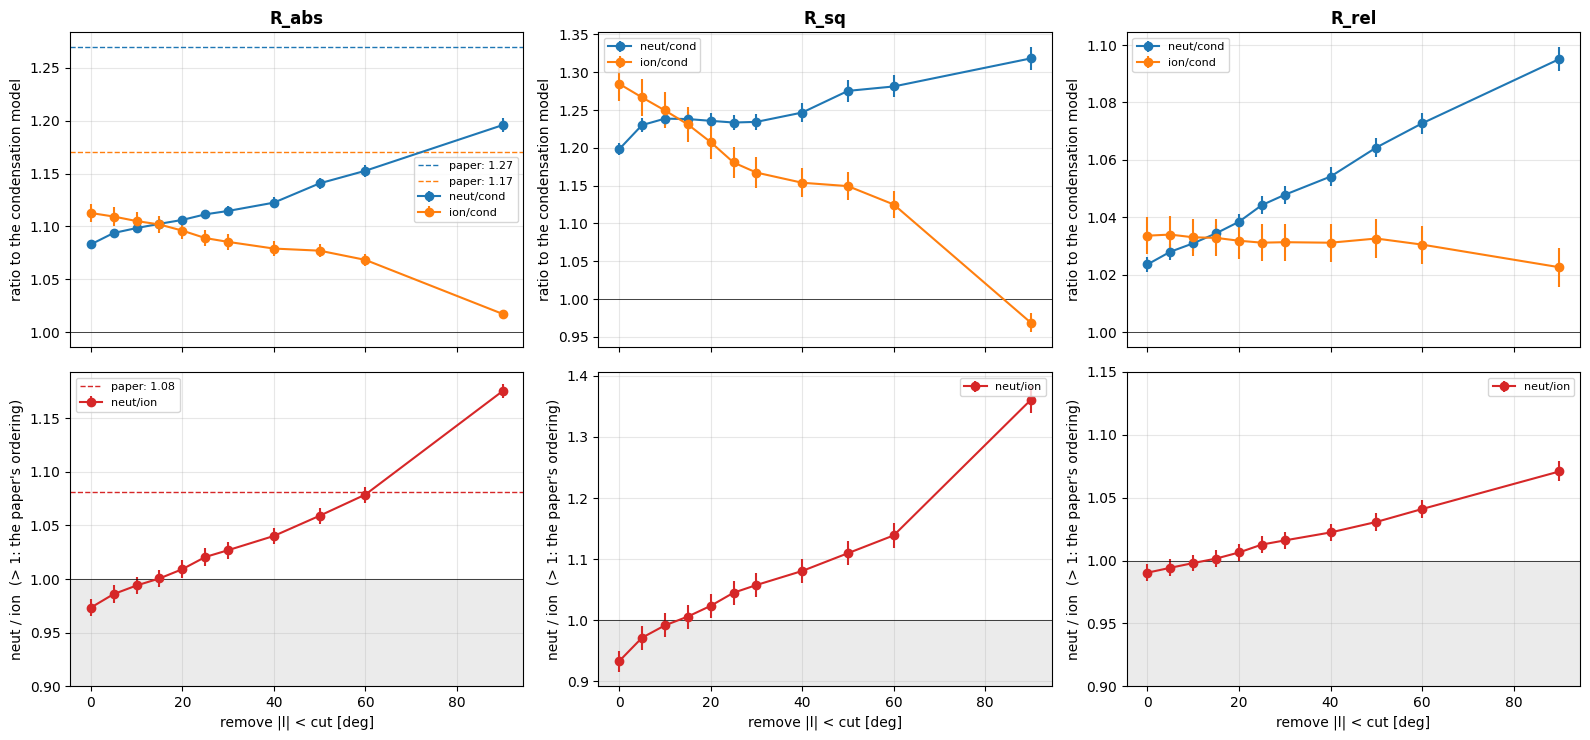

In [15]:
def fam_means(out, k):
    m, se = [], []
    for g in range(3):
        x = np.array([out[n]["R_" + k] for n in names_M[3 * g:3 * g + 3]]); m.append(x.mean()); se.append(x.std(ddof=1) / np.sqrt(len(x)))
    return np.array(m), np.array(se)

def ratio(m, se, a, b):
    r = m[a] / m[b]; return r, r * np.hypot(se[a] / m[a], se[b] / m[b])


cuts = sorted(SCAN)
ref = SCAN[cuts[0]][names_M[0]]["flux_lab"]

# (neut/cond, ion/cond, neut/ion), each (value, se)
R = {k: {c: [ratio(*fam_means(SCAN[c], k), 0, 2), 
             ratio(*fam_means(SCAN[c], k), 1, 2), 
             ratio(*fam_means(SCAN[c], k), 0, 1)] for c in cuts} for k in OBS}

fig, axs = plt.subplots(2, 3, figsize=(16, 7.5), sharex=True)
for j, k in enumerate(OBS):
    a = axs[0, j]

    for i, (lab_, col) in enumerate((("neut/cond", "C0"), ("ion/cond", "C1"))):
        a.errorbar(cuts, [R[k][c][i][0] for c in cuts], yerr=[R[k][c][i][1] for c in cuts], fmt="o-", color=col, label=lab_)
    
    if k == "abs":
        a.axhline(1.27, color="C0", ls="--", lw=1, label="paper: 1.27")
        a.axhline(1.17, color="C1", ls="--", lw=1, label="paper: 1.17")

    a.axhline(1.0, color="k", lw=0.5)
    a.set_title(f"R_{k}", weight="bold")
    a.set_ylabel("ratio to the condensation model")
    a.legend(fontsize=8); a.grid(alpha=0.3)
    
    a = axs[1, j]
    a.errorbar(cuts, [R[k][c][2][0] for c in cuts], yerr=[R[k][c][2][1] for c in cuts], fmt="o-", 
               color="C3", label="neut/ion")
    
    if k == "abs": 
        a.axhline(1.60 / 1.48, color="C3", ls="--", lw=1, label="paper: 1.08")

    a.axhline(1.0, color="k", lw=0.5)
    lo_, hi_ = a.get_ylim()
    a.set_ylim(min(lo_, 0.9), max(hi_, 1.15))
    lo_, hi_ = a.get_ylim()
    
    a.axhspan(lo_, 1.0, color="0.92", zorder=0)
    a.set_ylim(lo_, hi_)
    a.set_xlabel("remove |l| < cut [deg]")
    a.set_ylabel("neut / ion  (> 1: the paper's ordering)")
    a.legend(fontsize=8)
    a.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Now, we do the same for |b|.

R_abs: share of tot. neut-ion diff. @ |b| < 30:  163.1%   (tot. -0.036);   ion-cond:   33.9%   (tot. +0.123)
R_sq : share of tot. neut-ion diff. @ |b| < 30:   99.4%   (tot. -0.127);   ion-cond:   27.3%   (tot. +0.339)
R_rel: share of tot. neut-ion diff. @ |b| < 30:  218.5%   (tot. -0.011);   ion-cond:   16.9%   (tot. +0.041)


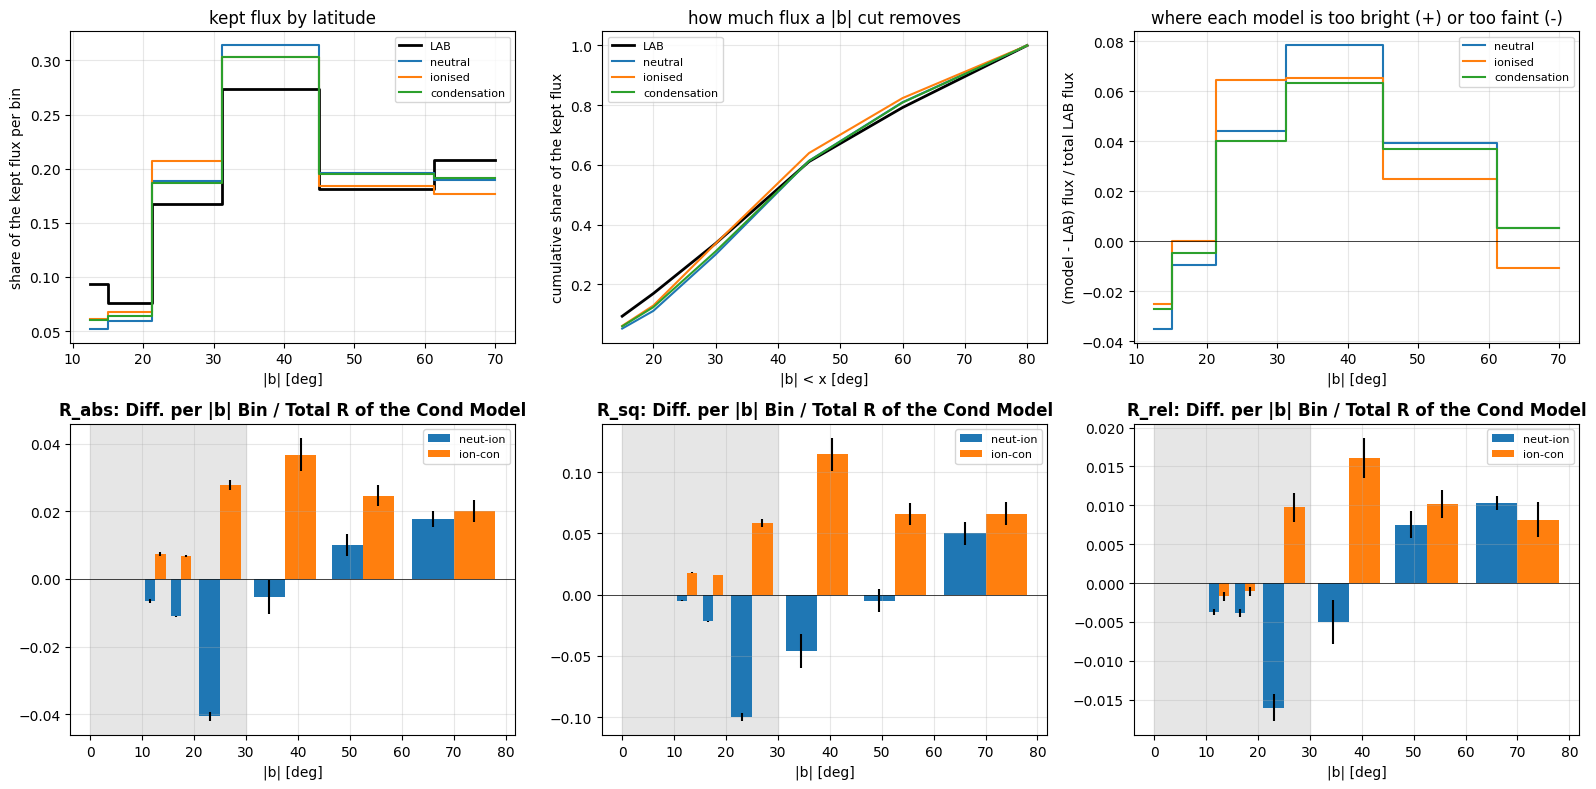

Bottom row: positive bars = the first model of the pair is worse in that bin. Grey band: |b| < 30 deg.


In [16]:
def share_by_b(cmp_obj, res):
    """LAB and model flux (weighted sums over the kept voxels) in latitude bins B_BINS; needs evaluate(keep_vectors=True)."""
    vec = res["vec"]; valid = vec["valid"]
    
    # Assuming |b| since B_BINS are positive, and assuming 'b' is the 2nd axis (v, b, l).
    # If 'b' is the 3rd axis in your cube, change [None, :, None] to [None, None, :]
    bw = np.broadcast_to(np.abs(cmp_obj.b)[None, :, None], valid.shape)[valid]
    
    w, d, m = vec["w"], vec["d"], vec["m"]
    sel = [(bw >= lo) & (bw < hi) for lo, hi in zip(B_BINS[:-1], B_BINS[1:])]
    return (np.array([(w * d)[s].sum() for s in sel]), 
            np.array([(w * m)[s].sum() for s in sel]), 
            np.array([s.sum() for s in sel]))

# (b) where in latitude does each model gain or lose
BASE = globals().get("BASE", {})

for g in range(3):
    for j, nm in enumerate(names_M[3 * g:3 * g + 3]):
        if nm in BASE: continue
        cube, ax_ = load_model(nm, GRID)
        BASE[nm] = cmp.evaluate(cmp.model_cmp(cube, ax_), keep_vectors=(j == 0))

bc = 0.5 * (B_BINS[:-1] + B_BINS[1:]); wbin = np.diff(B_BINS)
share = {LABELS[g]: share_by_b(cmp, BASE[names_M[3 * g]]) for g in range(3)}
fl_lab = share["neutral"][0]; tot = fl_lab.sum()

fig, axs = plt.subplots(2, 3, figsize=(16, 8))

ax = axs[0, 0]
ax.step(bc, fl_lab / tot, where="mid", color="k", lw=2, label="LAB")
for (name, (fl, fm, nv)), c in zip(share.items(), ("C0", "C1", "C2")): 
    ax.step(bc, fm / fm.sum(), where="mid", color=c, label=name)
ax.set_xlabel("|b| [deg]")
ax.set_ylabel("share of the kept flux per bin")
ax.set_title("kept flux by latitude")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axs[0, 1]
ab = bc
xs = B_BINS[1:] # cumulative tracking uses upper bin edges
ax.plot(xs, [fl_lab[ab < x].sum() / tot for x in xs], "k-", lw=2, label="LAB")
for (name, (fl, fm, nv)), c in zip(share.items(), ("C0", "C1", "C2")): 
    ax.plot(xs, [fm[ab < x].sum() / fm.sum() for x in xs], color=c, label=name)
ax.set_xlabel("|b| < x [deg]")
ax.set_ylabel("cumulative share of the kept flux")
ax.set_title("how much flux a |b| cut removes")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axs[0, 2]
for (name, (fl, fm, nv)), c in zip(share.items(), ("C0", "C1", "C2")): 
    ax.step(bc, (fm - fl) / tot, where="mid", color=c, label=name)
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("|b| [deg]")
ax.set_ylabel("(model - LAB) flux / total LAB flux")
ax.set_title("where each model is too bright (+) or too faint (-)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

inner = bc < 30
for a, k in zip(axs[1], OBS):
    Rb = [np.array([BASE[n]["by_b_" + k] for n in names_M[3 * g:3 * g + 3]]) for g in range(3)]        
    Rc_tot = Rb[2].sum(axis=1).mean()
    mean = [r.mean(axis=0) for r in Rb]; se = [r.std(axis=0, ddof=1) / np.sqrt(r.shape[0]) for r in Rb]
    d_ni, e_ni = (mean[0] - mean[1]) / Rc_tot, np.hypot(se[0], se[1]) / Rc_tot
    d_ic, e_ic = (mean[1] - mean[2]) / Rc_tot, np.hypot(se[1], se[2]) / Rc_tot
    
    width = wbin * 0.4
    offset = wbin * 0.2
    a.bar(bc - offset, d_ni, width, yerr=e_ni, color="C0", label="neut-ion")
    a.bar(bc + offset, d_ic, width, yerr=e_ic, color="C1", label="ion-con")
    
    a.axhline(0, color="k", lw=0.5); a.axvspan(0, 30, color="0.9", zorder=0)
    a.set_xlabel("|b| [deg]")
    a.set_title(f"R_{k}: Diff. per |b| Bin / Total R of the Cond Model", weight="bold")
    a.legend(fontsize=8)
    a.grid(alpha=0.3)

    print(f"R_{k:3s}: share of tot. neut-ion diff. @ |b| < 30: {100*d_ni[inner].sum()/d_ni.sum():6.1f}%"
          f"   (tot. {d_ni.sum():+.3f});   ion-cond: {100*d_ic[inner].sum()/d_ic.sum():6.1f}%   (tot. {d_ic.sum():+.3f})")

plt.tight_layout(); plt.show()
print("Bottom row: positive bars = the first model of the pair is worse in that bin. Grey band: |b| < 30 deg.")

In [17]:
# (c) the exact scan: remove |b| < cut from BOTH LAB and the models (and re-evaluated).
B_CUTS = [0, 5, 10, 15, 20, 25, 30, 40, 50, 60, 70]      # edit; cut = 0 is the baseline, 70 is max
SCAN_FILE = GRID / "marasco_bcut_scan.pkl"
SCAN_META = dict(B_CUT=B_CUT, L_CUT=L_CUT, REL_FLOOR=REL_FLOOR, names=tuple(names_M))
KEEP_KEYS = ("R_abs", "R_sq", "R_rel", "scale", "flux_lab", "n_valid")
SCAN = globals().get("SCAN", {})

if not SCAN and SCAN_FILE.exists():
    saved = pickle.load(open(SCAN_FILE, "rb"))
    if saved.get("meta") == SCAN_META: 
        SCAN = saved["scan"]
    else: 
        print("Cached scan was made with other settings (B_CUT / L_CUT / REL_FLOOR / cubes) and is ignored).")
        print("It is overwritten when the scan runs.")


for cut in B_CUTS:
    if cut in SCAN: continue
    t0 = time.time()

    drop = (lambda l, b, v, c=cut: (np.abs(b) < c)[None, :, None]) if cut > 0 else None
    
    cv = make_cmp_variant(drop=drop); out = {}
    for nm in names_M:
        cube, ax_ = load_model(nm, GRID)
        r = cv.evaluate(cv.model_cmp(cube, ax_))
        out[nm] = {k: r[k] for k in KEEP_KEYS}
        
    SCAN[cut] = out
    pickle.dump(dict(meta=SCAN_META, scan=SCAN), open(SCAN_FILE, "wb"))
    print(f"|b| > {cut}: done in {time.time()-t0:.0f} s")

|b| > 70: done in 23 s


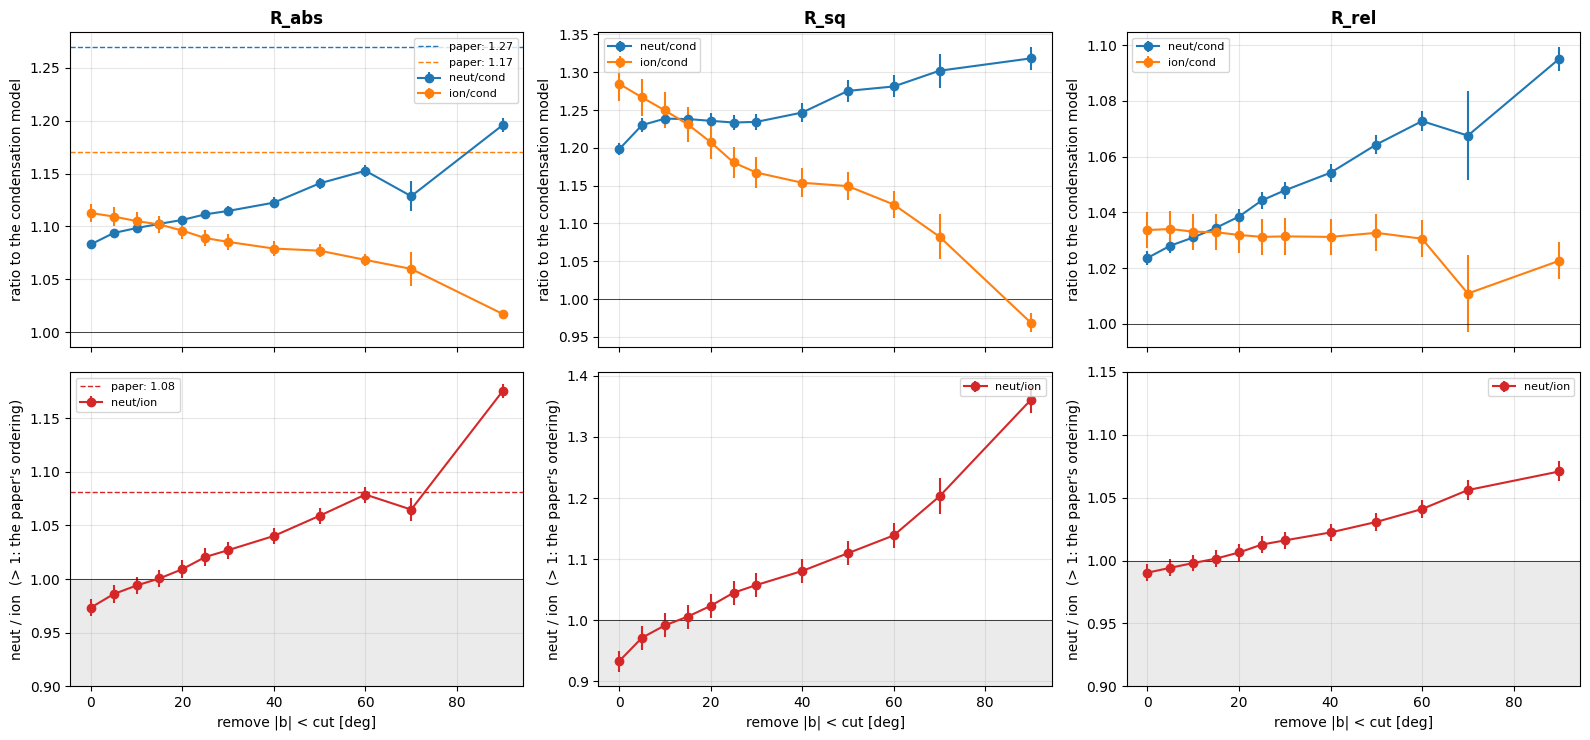

In [18]:
cuts = sorted(SCAN)
ref = SCAN[cuts[0]][names_M[0]]["flux_lab"]

# (neut/cond, ion/cond, neut/ion), each (value, se)
R = {k: {c: [ratio(*fam_means(SCAN[c], k), 0, 2), 
             ratio(*fam_means(SCAN[c], k), 1, 2), 
             ratio(*fam_means(SCAN[c], k), 0, 1)] for c in cuts} for k in OBS}   

fig, axs = plt.subplots(2, 3, figsize=(16, 7.5), sharex=True)
for j, k in enumerate(OBS):
    a = axs[0, j]
    for i, (lab_, col) in enumerate((("neut/cond", "C0"), ("ion/cond", "C1"))):
        a.errorbar(cuts, [R[k][c][i][0] for c in cuts], yerr=[R[k][c][i][1] for c in cuts], fmt="o-", color=col, label=lab_)
    if k == "abs": 
        a.axhline(1.27, color="C0", ls="--", lw=1, label="paper: 1.27")
        a.axhline(1.17, color="C1", ls="--", lw=1, label="paper: 1.17")

    a.axhline(1.0, color="k", lw=0.5)
    a.set_title(f"R_{k}", weight="bold")
    a.set_ylabel("ratio to the condensation model")
    a.legend(fontsize=8)
    a.grid(alpha=0.3)
    
    a = axs[1, j]
    a.errorbar(cuts, [R[k][c][2][0] for c in cuts], yerr=[R[k][c][2][1] for c in cuts], 
               fmt="o-", color="C3", label="neut/ion")
    if k == "abs": 
        a.axhline(1.60 / 1.48, color="C3", ls="--", lw=1, label="paper: 1.08")

    a.axhline(1.0, color="k", lw=0.5)
    lo_, hi_ = a.get_ylim()
    a.set_ylim(min(lo_, 0.9), max(hi_, 1.15))
    lo_, hi_ = a.get_ylim()

    a.axhspan(lo_, 1.0, color="0.92", zorder=0)
    a.set_ylim(lo_, hi_)
    
    a.set_xlabel("remove |b| < cut [deg]")
    a.set_ylabel("neut / ion  (> 1: the paper's ordering)")
    a.legend(fontsize=8)
    a.grid(alpha=0.3)
    
plt.tight_layout()
plt.show()

So, we see that there is not real plateauing with increasing |l| or |b| cuts and moreover, they reduce the ion/cond ratio towards 1, which it shoulding. There is a hint of plateauing near |l| or |b| ~ 30, but I don't know the physical reasoning behind that since I do not see it for all residuals as clearly for how I see it in `R_sq` and the fact that it starts dipping after |l| or |b| ~ 50, puts this into question for me.

The physical intuition was that it is the GC/bar, and it might still be true, but I am unable to justify a 30 deg cut by itself, especially with limited plateauing, so I leave this for further consideration.